In [ ]:
import os

# Convert the raw UCI .txt (';'-separated, '?' = missing) to CSV once
if not os.path.exists('household_power_consumption.csv'):
    with open('household_power_consumption.txt', newline='') as src, open('household_power_consumption.csv', 'w', newline='') as dst:
        for line in src:
            dst.write(line.replace(';', ',').replace('?', ''))

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## Basic investigation

In [2]:
print('Shape:', df.shape)
print('Range:', df.index.min(), '->', df.index.max())
print('Timestamps unique and evenly spaced (1 min):', df.index.is_unique and (df.index.to_series().diff().dropna() == pd.Timedelta('1min')).all())
df.info()

Shape: (2075259, 7)
Range: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Timestamps unique and evenly spaced (1 min): True
<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000


### Missing values

In [4]:
missing = df.isna()
print('Missing per column:')
print(missing.sum())
print(f'\nRows with any missing: {missing.any(axis=1).sum()} ({missing.any(axis=1).mean():.2%})')

# Missing values come in contiguous gaps; list the longest ones
row_missing = missing.any(axis=1)
gap_id = (row_missing != row_missing.shift()).cumsum()
gaps = row_missing[row_missing].groupby(gap_id[row_missing]).agg(
    start=lambda s: s.index.min(), end=lambda s: s.index.max(), minutes='size')
print(f'\nNumber of gaps: {len(gaps)}')
gaps.sort_values('minutes', ascending=False).head(10).reset_index(drop=True)

Missing per column:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Rows with any missing: 25979 (1.25%)

Number of gaps: 71


,start,end,minutes
0,2010-08-17 21:02:00,2010-08-22 21:27:00,7226
1,2010-09-25 03:56:00,2010-09-28 19:12:00,5237
2,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
3,2009-06-13 00:30:00,2009-06-15 07:34:00,3305
4,2010-01-12 14:53:00,2010-01-14 19:01:00,3129
5,2010-03-20 03:52:00,2010-03-21 13:38:00,2027
6,2009-08-13 05:00:00,2009-08-13 19:50:00,891
7,2007-07-15 16:49:00,2007-07-15 18:11:00,83
8,2008-12-10 10:48:00,2008-12-10 11:57:00,70
9,2007-07-15 18:21:00,2007-07-15 19:07:00,47


### Distributions

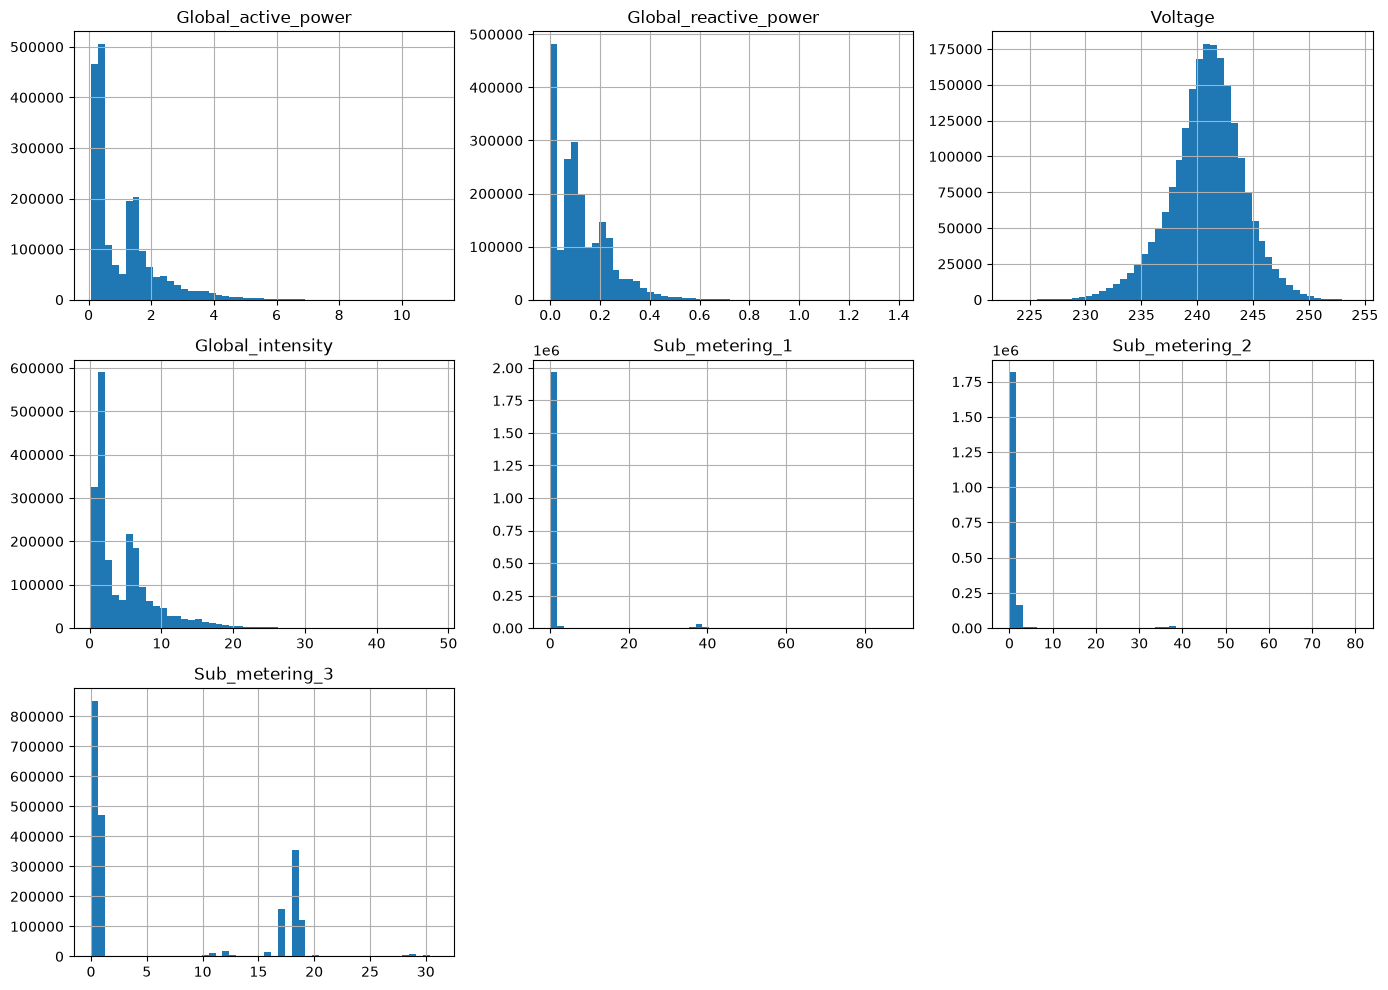

In [5]:
df.hist(bins=50, figsize=(14, 10))
plt.tight_layout()
plt.show()

### Correlations

In [6]:
df.corr().round(2)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.00,0.25,-0.40,1.00,0.48,0.43,0.64
Global_reactive_power,0.25,1.00,-0.11,0.27,0.12,0.14,0.09
Voltage,-0.40,-0.11,1.00,-0.41,-0.20,-0.17,-0.27
Global_intensity,1.00,0.27,-0.41,1.00,0.49,0.44,0.63
Sub_metering_1,0.48,0.12,-0.20,0.49,1.00,0.05,0.10
Sub_metering_2,0.43,0.14,-0.17,0.44,0.05,1.00,0.08
Sub_metering_3,0.64,0.09,-0.27,0.63,0.10,0.08,1.00


### Trends and seasonality

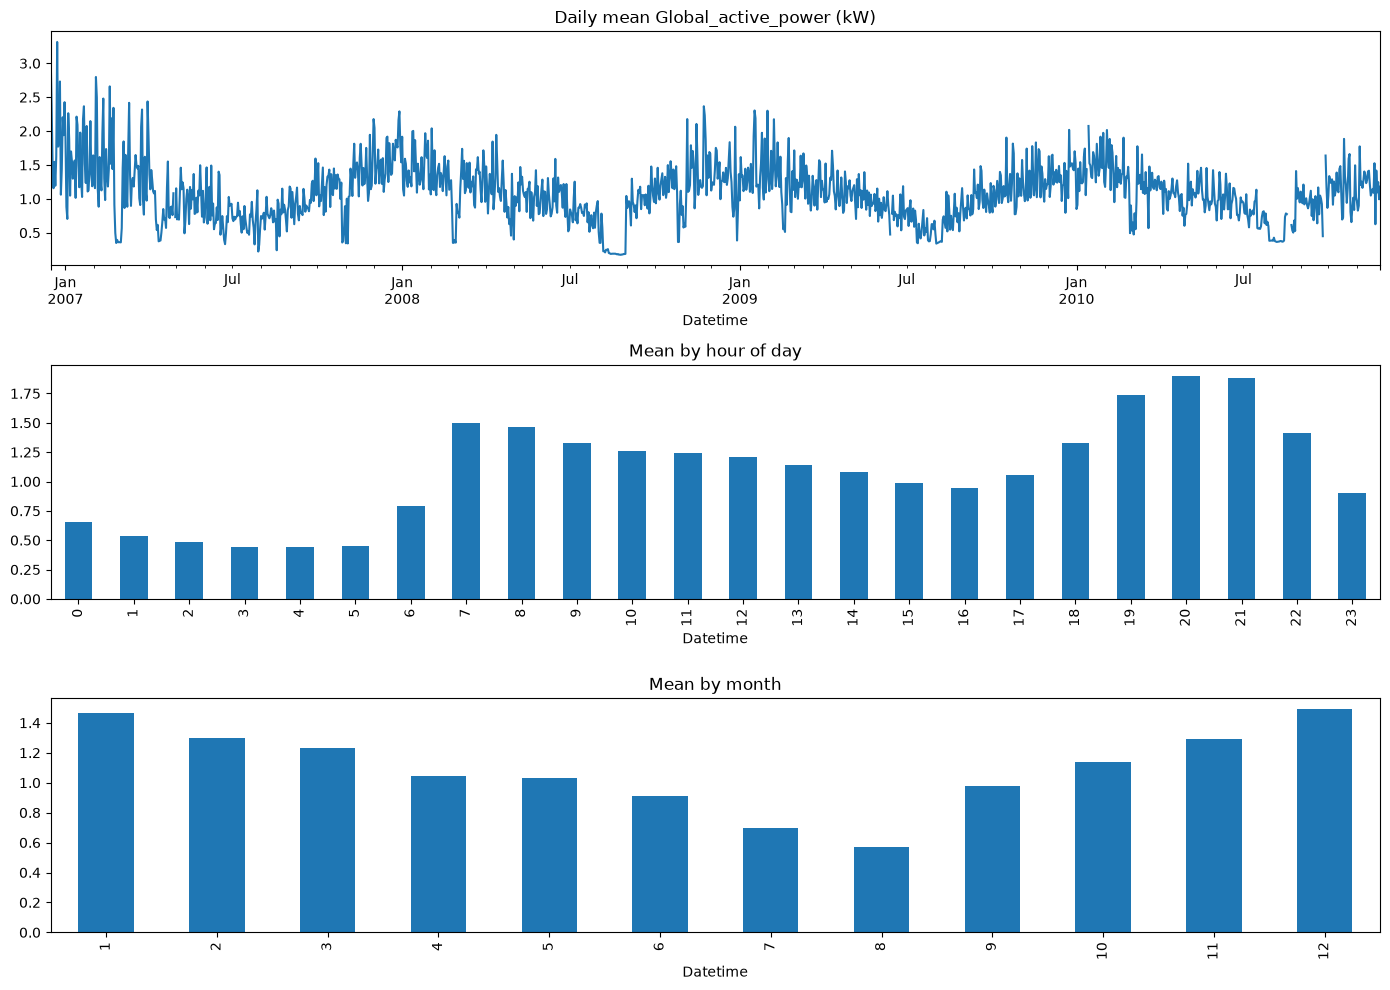

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
df['Global_active_power'].resample('D').mean().plot(ax=axes[0], title='Daily mean Global_active_power (kW)')
df['Global_active_power'].groupby(df.index.hour).mean().plot(ax=axes[1], kind='bar', title='Mean by hour of day')
df['Global_active_power'].groupby(df.index.month).mean().plot(ax=axes[2], kind='bar', title='Mean by month')
plt.tight_layout()
plt.show()